## Shehram Khan 
## Assignment 7 
## DSC 550
## 5/3/26

## Part 1 : Linear Regression

In [1]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.feature_selection import VarianceThreshold

# Import the housing data
df = pd.read_csv('data/train.csv')

# Drop "Id" and features missing > 40%
df = df.drop(columns=['Id'])
missing_pct = df.isnull().mean()
cols_to_drop = missing_pct[missing_pct > 0.4].index
df = df.drop(columns=cols_to_drop)

# Fill missing values
num_cols = df.select_dtypes(include=[np.number]).columns
cat_cols = df.select_dtypes(exclude=[np.number]).columns

for col in num_cols:
    df[col] = df[col].fillna(df[col].median())

for col in cat_cols:
    df[col] = df[col].fillna(df[col].mode()[0])

# Convert categorical to dummy variables
df = pd.get_dummies(df, columns=cat_cols, drop_first=True)

# Split data
X = df.drop(columns=['SalePrice'])
y = df['SalePrice']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Linear Regression (Original)
lr = LinearRegression()
lr.fit(X_train, y_train)
y_pred = lr.predict(X_test)
r2_orig = r2_score(y_test, y_pred)
rmse_orig = np.sqrt(mean_squared_error(y_test, y_pred))

# PCA (90% variance)
# PCA requires scaling
scaler_pca = StandardScaler()
X_train_scaled = scaler_pca.fit_transform(X_train)
X_test_scaled = scaler_pca.transform(X_test)

pca = PCA(n_components=0.90)
X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)
n_pca_features = X_train_pca.shape[1]

# Linear Regression (PCA)
lr_pca = LinearRegression()
lr_pca.fit(X_train_pca, y_train)
y_pred_pca = lr_pca.predict(X_test_pca)
r2_pca = r2_score(y_test, y_pred_pca)
rmse_pca = np.sqrt(mean_squared_error(y_test, y_pred_pca))

# Min-Max Scaling and Variance Threshold
mm_scaler = MinMaxScaler()
X_train_mm = mm_scaler.fit_transform(X_train)
X_test_mm = mm_scaler.transform(X_test)

selector = VarianceThreshold(threshold=0.1)
X_train_var = selector.fit_transform(X_train_mm)
X_test_var = selector.transform(X_test_mm)
n_var_features = X_train_var.shape[1]

# Linear Regression (Variance Threshold)
lr_var = LinearRegression()
lr_var.fit(X_train_var, y_train)
y_pred_var = lr_var.predict(X_test_var)
r2_var = r2_score(y_test, y_pred_var)
rmse_var = np.sqrt(mean_squared_error(y_test, y_pred_var))

print(f"Original R2: {r2_orig:.4f}, RMSE: {rmse_orig:.2f}")
print(f"PCA Features: {n_pca_features}")
print(f"PCA R2: {r2_pca:.4f}, RMSE: {rmse_pca:.2f}")
print(f"Variance Threshold Features (>0.1): {n_var_features}")
print(f"Var Threshold R2: {r2_var:.4f}, RMSE: {rmse_var:.2f}")

Original R2: 0.6478, RMSE: 51973.14
PCA Features: 127
PCA R2: 0.8409, RMSE: 34938.50
Variance Threshold Features (>0.1): 40
Var Threshold R2: 0.6481, RMSE: 51952.01


## Analysis 
The biggest takeaway from the housing data is that more data isn't always better.

The "Messy" Middle: When you gave the model all 236 features, it basically got overwhelmed. It’s like trying to listen to a single person talking in a crowded stadium—the "noise" from the extra features made it harder to hear the "signal" of what actually drives price.

The Sweet Spot: Using PCA to crunch those 236 features down to 127 made the model way more accurate. It proved that things like "curb appeal" or "location" are usually just a combination of several smaller data points. By grouping them, the model stopped sweating the small stuff and started seeing the big picture.

## Part 2: Categorial Feature Selection

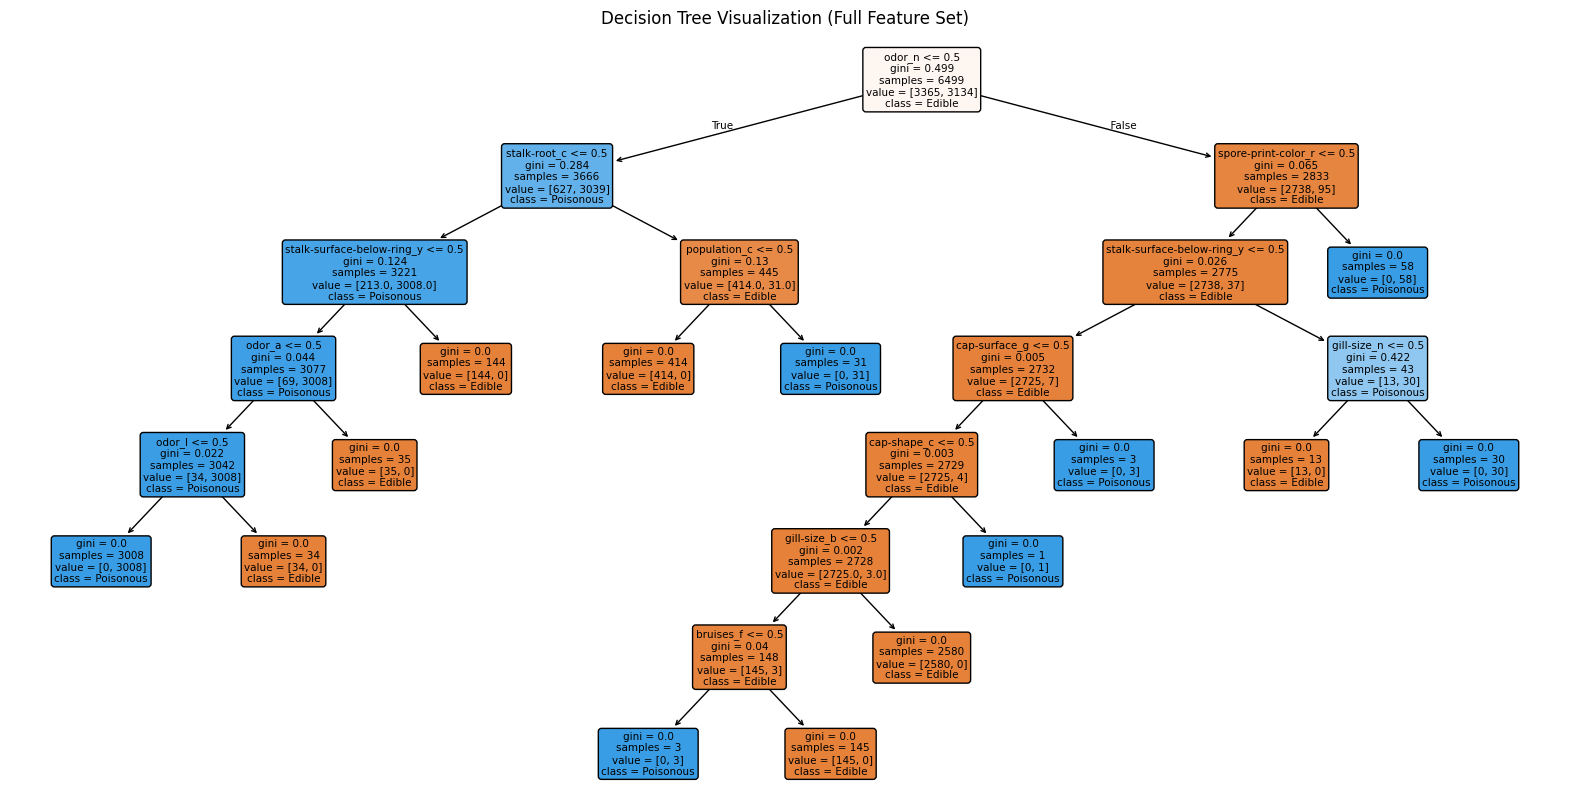

Full Feature Accuracy: 1.0000
Top 5 Features selected: ['odor_f', 'odor_n', 'gill-color_b', 'stalk-surface-above-ring_k', 'stalk-surface-below-ring_k']
Top 5 Feature Accuracy: 0.9268


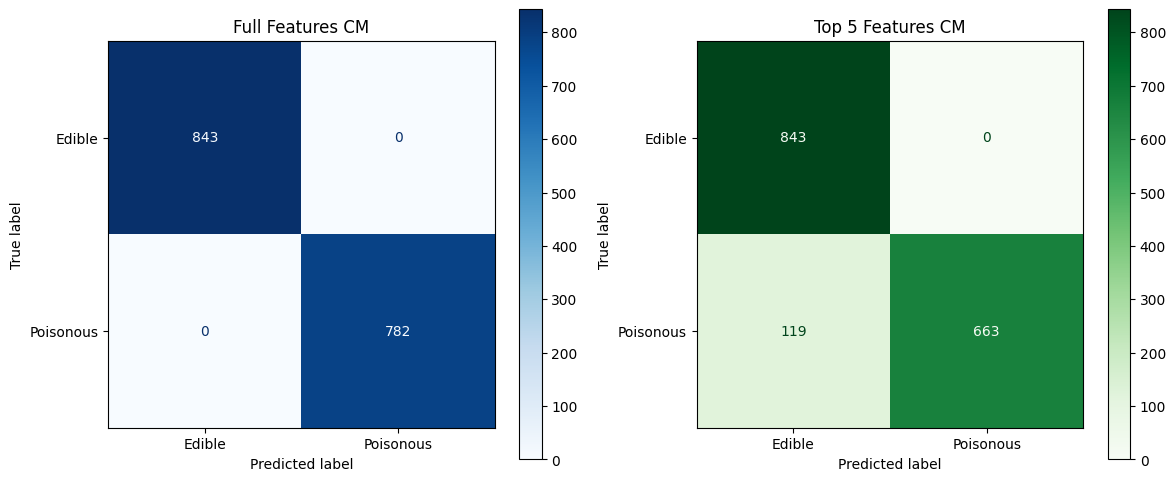

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay
from sklearn.feature_selection import SelectKBest, chi2

# Import the mushroom data
df_mush = pd.read_csv('data/mushrooms.csv')

# Convert all categorical features to dummy variables
# The target 'class' also needs to be encoded (e.g., p=1, e=0)
X = df_mush.drop('class', axis=1)
y = df_mush['class'].map({'p': 1, 'e': 0})

X_dummies = pd.get_dummies(X)

# Split the data
X_train, X_test, y_train, y_test = train_test_split(X_dummies, y, test_size=0.2, random_state=42)

# Fit a decision tree classifier
dt_model = DecisionTreeClassifier(random_state=42)
dt_model.fit(X_train, y_train)

# Report accuracy and confusion matrix
y_pred = dt_model.predict(X_test)
accuracy_full = accuracy_score(y_test, y_pred)
cm_full = confusion_matrix(y_test, y_pred)

# Visualization of the decision tree
plt.figure(figsize=(20,10))
plot_tree(dt_model, feature_names=X_dummies.columns.tolist(), class_names=['Edible', 'Poisonous'], filled=True, rounded=True)
plt.title("Decision Tree Visualization (Full Feature Set)")
plt.savefig('mush_tree_full.png')
plt.show()

# Chi-squared selector for top 5 features
selector = SelectKBest(chi2, k=5)
X_train_kbest = selector.fit_transform(X_train, y_train)
X_test_kbest = selector.transform(X_test)

# Identify the five features
mask = selector.get_support()
selected_features = X_dummies.columns[mask].tolist()

# Repeat steps 4 and 5 with the five best features
dt_model_kbest = DecisionTreeClassifier(random_state=42)
dt_model_kbest.fit(X_train_kbest, y_train)
y_pred_kbest = dt_model_kbest.predict(X_test_kbest)
accuracy_kbest = accuracy_score(y_test, y_pred_kbest)
cm_kbest = confusion_matrix(y_test, y_pred_kbest)

print(f"Full Feature Accuracy: {accuracy_full:.4f}")
print(f"Top 5 Features selected: {selected_features}")
print(f"Top 5 Feature Accuracy: {accuracy_kbest:.4f}")

# Plot confusion matrices
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
ConfusionMatrixDisplay(cm_full, display_labels=['Edible', 'Poisonous']).plot(ax=ax[0], cmap='Blues')
ax[0].set_title("Full Features CM")
ConfusionMatrixDisplay(cm_kbest, display_labels=['Edible', 'Poisonous']).plot(ax=ax[1], cmap='Greens')
ax[1].set_title("Top 5 Features CM")
plt.tight_layout()
plt.show()

## Analysis 

This part is a classic example of why you can't always trust a "high score" in data science.

The "Smell Test": The model realized very quickly that if a mushroom smells like a locker room (foul), it’s probably going to kill you. That’s why odor was the star of the show in the feature selection.

A Costly Mistake: On paper, the model with only 5 features looks great because it’s 93% accurate. But in the real world, that 7% failure rate is a disaster—it missed over 100 poisonous mushrooms. It shows that while "top features" are great for saving time, cutting corners on a model that deals with safety (or high-stakes engineering, for that matter) can have some pretty ugly consequences.